# Gradient Descent

In [1]:
import pandas as pd
import numpy as np
import torch


In [2]:
df=pd.read_csv("bonus.csv")
df.head()

,employee_id,performance,years_of_experience,projects_completed,bonus
0,EMP_001,7,1,3,116
1,EMP_002,4,8,10,136
2,EMP_003,8,4,5,150
3,EMP_004,5,4,7,118
4,EMP_005,7,5,6,146


In [3]:
bonus=torch.tensor(df["bonus"].values,dtype=torch.float32,device="cuda")
performance=torch.tensor(df["performance"].values,dtype=torch.float32,device="cuda")
years_of_experience=torch.tensor(df["years_of_experience"].values,dtype=torch.float32,device="cuda")
projects_completed=torch.tensor(df["projects_completed"].values,dtype=torch.float32,device="cuda")

In [4]:
device="cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [5]:
#Initialize weights
w1=torch.rand(1,requires_grad=True,device=device)
w2=torch.rand(1,requires_grad=True,device=device)
w3=torch.rand(1,requires_grad=True,device=device)
b=torch.rand(1,requires_grad=True,device=device)

#Learning Rate, epochs 
lr=0.001
epochs=5000
#  Run the loop
for epoch in range(epochs):
    pred_bonus=w1*performance+w2*years_of_experience+w3*projects_completed+b
    loss=((pred_bonus-bonus)**2).mean()

    loss.backward()
    with torch.no_grad():
        w1-=lr*w1.grad
        w2-=lr*w2.grad
        w3-=lr*w3.grad
        b-=lr*b.grad
    w1.grad.zero_()
    w2.grad.zero_()
    w3.grad.zero_()
    b.grad.zero_()

    if (epoch+1)%100==0:
        print(f"Epochs : {epoch+1}\t Loss : {loss.item():.2f}")

Epochs : 100	 Loss : 32.46
Epochs : 200	 Loss : 22.50
Epochs : 300	 Loss : 21.76
Epochs : 400	 Loss : 21.16
Epochs : 500	 Loss : 20.59
Epochs : 600	 Loss : 20.04
Epochs : 700	 Loss : 19.51
Epochs : 800	 Loss : 19.00
Epochs : 900	 Loss : 18.50
Epochs : 1000	 Loss : 18.03
Epochs : 1100	 Loss : 17.56
Epochs : 1200	 Loss : 17.11
Epochs : 1300	 Loss : 16.67
Epochs : 1400	 Loss : 16.25
Epochs : 1500	 Loss : 15.83
Epochs : 1600	 Loss : 15.43
Epochs : 1700	 Loss : 15.04
Epochs : 1800	 Loss : 14.66
Epochs : 1900	 Loss : 14.29
Epochs : 2000	 Loss : 13.93
Epochs : 2100	 Loss : 13.58
Epochs : 2200	 Loss : 13.23
Epochs : 2300	 Loss : 12.90
Epochs : 2400	 Loss : 12.58
Epochs : 2500	 Loss : 12.26
Epochs : 2600	 Loss : 11.95
Epochs : 2700	 Loss : 11.65
Epochs : 2800	 Loss : 11.36
Epochs : 2900	 Loss : 11.07
Epochs : 3000	 Loss : 10.79
Epochs : 3100	 Loss : 10.52
Epochs : 3200	 Loss : 10.25
Epochs : 3300	 Loss : 10.00
Epochs : 3400	 Loss : 9.74
Epochs : 3500	 Loss : 9.50
Epochs : 3600	 Loss : 9.26
Epoc

# Datasets and data loaders

In [6]:
import torch 
from torchvision import datasets
from torchvision.transforms import ToTensor,transforms


In [7]:
transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize(0.5,0.5)])
train_dataset=datasets.MNIST(root="/data",train=True,transform=transform,download=True)
test_dataset=datasets.MNIST(root="/data",train=False,transform=transform,download=True)

In [8]:
from torch.utils.data import DataLoader
train_loader=DataLoader(train_dataset,batch_size=64,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=64,shuffle=False)

In [9]:
classes=train_dataset.classes
classes

['0 - zero',
 '1 - one',
 '2 - two',
 '3 - three',
 '4 - four',
 '5 - five',
 '6 - six',
 '7 - seven',
 '8 - eight',
 '9 - nine']

In [10]:
for images,labels in train_loader:
    print(images.shape)
    break


torch.Size([64, 1, 28, 28])


28 X 28 pixcel image

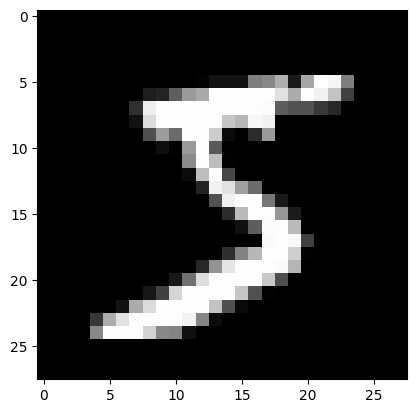

In [11]:
import matplotlib.pyplot as plt 
images,labels =train_dataset[0]
plt.imshow(images.squeeze(),cmap='grey')
plt.show()


In [12]:
labels

5

In [13]:
import torch.nn as nn 
import torch.optim as optim 
import torch 

In [14]:
class MinimstClassification(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28,128),
            nn.ReLU(),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Linear(64,32),
            nn.ReLU(),
            nn.Linear(32,16),
            nn.ReLU(),
            nn.Linear(16,10),
            nn.Softmax()
        )
    def forward(self,x):
        return self.network(x)
    

model=MinimstClassification().to(device)
model

MinimstClassification(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=32, bias=True)
    (6): ReLU()
    (7): Linear(in_features=32, out_features=16, bias=True)
    (8): ReLU()
    (9): Linear(in_features=16, out_features=10, bias=True)
    (10): Softmax(dim=None)
  )
)

In [15]:
optimizer=optim.Adam(model.parameters(),lr=0.001)
loss_fn=nn.CrossEntropyLoss()
epochs=6
for epoch in range(epochs):
    running_loss=0.0
    for images,labels in train_loader:
        #forward pass
        images=images.to(device)
        labels=labels.to(device)
        pred=model(images)
        loss=loss_fn(pred,labels)
        #backward pass
        optimizer.zero_grad()
        loss.backward()
        #updating weights
        optimizer.step()
        running_loss+=loss.item()
    print(f"Epoch : {epoch}, Loss : {running_loss/len(train_loader)}")
model.eval()
total=0
correct=0
with torch.no_grad():
    for images,labels in test_loader:
        labels=labels.to(device)
        images=images.to(device)
        output=model(images)
        _,pred=torch.max(output.data,1)
        correct+=(pred==labels).sum().item()
        total+=labels.size(0)
    print(f"Accuracy:  {100*(correct/total):.2f}%")

        

c:\Users\Trijesh Kondapuram\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\nn\modules\module.py:1736: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


Epoch : 0, Loss : 1.8030545541218348
Epoch : 1, Loss : 1.5871097417528441
Epoch : 2, Loss : 1.5530643766876986
Epoch : 3, Loss : 1.5366782844702065
Epoch : 4, Loss : 1.5262782431360502
Epoch : 5, Loss : 1.5195655390652003
Accuracy:  94.02%


In [16]:
model.eval()
all_predicted,all_labels=[],[]
with torch.no_grad():
    for images, labels in test_loader:
        outputs=model(images)
        _,pred=torch.max(outputs,1)
        all_predicted.extend(pred.numpy())
        all_labels.extend(labels.numpy())

# Classification Report
from sklearn.metrics import classification_report
cr=classification_report(all_labels,all_predicted)
print(cr)

RuntimeError: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu! (when checking argument for argument mat1 in method wrapper_CUDA_addmm)

# optimization techniques 

### Training Algorithms

GD with Momentum

In [ ]:
optimizer=optim.SGD(model.parameters(),lr=0.001,momentum=0.9)
loss_fn=nn.CrossEntropyLoss()
epochs=6
for epoch in range(epochs):
    running_loss=0.0
    for images,labels in train_loader:
        #forward pass
        images=images.to(device)
        labels=labels.to(device)
        pred=model(images)
        loss=loss_fn(pred,labels)
        #backward pass
        optimizer.zero_grad()
        loss.backward()
        #updating weights
        optimizer.step()
        running_loss+=loss.item()
    print(f"Epoch : {epoch}, Loss : {running_loss/len(train_loader)}")
model.eval()
total=0
correct=0
with torch.no_grad():
    for images,labels in test_loader:
        labels=labels.to(device)
        images=images.to(device)
        output=model(images)
        _,pred=torch.max(output.data,1)
        correct+=(pred==labels).sum().item()
        total+=labels.size(0)
    print(f"Accuracy:  {100*(correct/total):.2f}%")

        

c:\Users\Trijesh Kondapuram\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\nn\modules\module.py:1736: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


Epoch : 0, Loss : 1.5043427538770093
Epoch : 1, Loss : 1.5012163669824092
Epoch : 2, Loss : 1.500052376215392
Epoch : 3, Loss : 1.4992922905411548
Epoch : 4, Loss : 1.4987035209436153
Epoch : 5, Loss : 1.4982724177049422
Accuracy:  95.84%


RMS Prop

In [ ]:
optimizer=optim.RMSprop(model.parameters(),lr=0.001,alpha=0.9)
loss_fn=nn.CrossEntropyLoss()
epochs=6
for epoch in range(epochs):
    running_loss=0.0
    for images,labels in train_loader:
        #forward pass
        images=images.to(device)
        labels=labels.to(device)
        pred=model(images)
        loss=loss_fn(pred,labels)
        #backward pass
        optimizer.zero_grad()
        loss.backward()
        #updating weights
        optimizer.step()
        running_loss+=loss.item()
    print(f"Epoch : {epoch}, Loss : {running_loss/len(train_loader)}")
model.eval()
total=0
correct=0
with torch.no_grad():
    for images,labels in test_loader:
        labels=labels.to(device)
        images=images.to(device)
        output=model(images)
        _,pred=torch.max(output.data,1)
        correct+=(pred==labels).sum().item()
        total+=labels.size(0)
    print(f"Accuracy:  {100*(correct/total):.2f}%")

        

c:\Users\Trijesh Kondapuram\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\nn\modules\module.py:1736: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


Epoch : 0, Loss : 1.5131529933099808
Epoch : 1, Loss : 1.5108327296242785
Epoch : 2, Loss : 1.5078404350067252
Epoch : 3, Loss : 1.506854649291618
Epoch : 4, Loss : 1.5056589497432018
Epoch : 5, Loss : 1.5045146892574042
Accuracy:  95.77%


### Regularization Techniques

In [ ]:
class MinimstClassification(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28,128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(64,32),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(32,16),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(16,10),
            nn.Softmax()
        )
    def forward(self,x):
        return self.network(x)
    

model=MinimstClassification().to(device)
model

MinimstClassification(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.5, inplace=False)
    (7): Linear(in_features=64, out_features=32, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.5, inplace=False)
    (10): Linear(in_features=32, out_features=16, bias=True)
    (11): ReLU()
    (12): Dropout(p=0.5, inplace=False)
    (13): Linear(in_features=16, out_features=10, bias=True)
    (14): Softmax(dim=None)
  )
)

In [ ]:
optimizer=optim.Adam(model.parameters(),lr=0.001)
loss_fn=nn.CrossEntropyLoss()
epochs=6
for epoch in range(epochs):
    running_loss=0.0
    for images,labels in train_loader:
        #forward pass
        images=images.to(device)
        labels=labels.to(device)
        pred=model(images)
        loss=loss_fn(pred,labels)
        #backward pass
        optimizer.zero_grad()
        loss.backward()
        #updating weights
        optimizer.step()
        running_loss+=loss.item()
    print(f"Epoch : {epoch}, Loss : {running_loss/len(train_loader)}")
model.eval()
total=0
correct=0
with torch.no_grad():
    for images,labels in test_loader:
        labels=labels.to(device)
        images=images.to(device)
        output=model(images)
        _,pred=torch.max(output.data,1)
        correct+=(pred==labels).sum().item()
        total+=labels.size(0)
    print(f"Accuracy:  {100*(correct/total):.2f}%")


c:\Users\Trijesh Kondapuram\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\nn\modules\module.py:1736: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


Epoch : 0, Loss : 2.129601671751628
Epoch : 1, Loss : 2.010830591609483
Epoch : 2, Loss : 1.9469603882161284
Epoch : 3, Loss : 1.916202813831728
Epoch : 4, Loss : 1.8975336849054039
Epoch : 5, Loss : 1.8909840015714356
Accuracy:  64.71%


Batch Normalization

In [ ]:
class MinimstClassification(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28,128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128,64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Linear(64,32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Linear(32,16),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.Linear(16,10),
            nn.Softmax()
        )
    def forward(self,x):
        return self.network(x)
    

model__=MinimstClassification().to(device)
model__

MinimstClassification(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Linear(in_features=64, out_features=32, bias=True)
    (8): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Linear(in_features=32, out_features=16, bias=True)
    (11): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): Linear(in_features=16, out_features=10, bias=True)
    (14): Softmax(dim=None)
  )
)

In [ ]:
optimizer=optim.Adam(model.parameters(),lr=0.001)
loss_fn=nn.CrossEntropyLoss()
epochs=6
for epoch in range(epochs):
    running_loss=0.0
    for images,labels in train_loader:
        #forward pass
        images=images.to(device)
        labels=labels.to(device)
        pred=model__(images)
        loss=loss_fn(pred,labels)
        #backward pass
        optimizer.zero_grad()
        loss.backward()
        #updating weights
        optimizer.step()
        running_loss+=loss.item()
    print(f"Epoch : {epoch}, Loss : {running_loss/len(train_loader)}")
model.eval()
total=0
correct=0
with torch.no_grad():
    for images,labels in test_loader:
        labels=labels.to(device)
        images=images.to(device)
        output=model__(images)
        _,pred=torch.max(output.data,1)
        correct+=(pred==labels).sum().item()
        total+=labels.size(0)
    print(f"Accuracy:  {100*(correct/total):.2f}%")


c:\Users\Trijesh Kondapuram\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\nn\modules\module.py:1736: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


Epoch : 0, Loss : 2.3075149341432777
Epoch : 1, Loss : 2.3074227553694997
Epoch : 2, Loss : 2.307530639268188
Epoch : 3, Loss : 2.307538266883476
Epoch : 4, Loss : 2.3074343290918673
Epoch : 5, Loss : 2.307501952785419
Accuracy:  6.94%


In [ ]:
# Early stopping
class MinimstClassification(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28,128),
            nn.ReLU(),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Linear(64,32),
            nn.ReLU(),
            nn.Linear(32,16),
            nn.ReLU(),
            nn.Linear(16,10),
            nn.Softmax()
        )
    def forward(self,x):
        return self.network(x)
    

model=MinimstClassification().to(device)
model


In [21]:
from sklearn.metrics import accuracy_score


def earlyStopping(model,train_loader,val_loader,loss_fn,optimizer,epochs=20):
    train_losses,val_losses,val_accuracies=[],[],[]
    best_accuracy=0
    patience=0
    counter=0
    for epoch in range(epochs):
        model.train()
        running_loss=0.0
        for images,labels in train_loader:
            outputs=model(images.to(device))
            loss=loss_fn(outputs,labels.to(device))
            loss.backward()
            optimizer.zero_grad()
            optimizer.step()
            running_loss+=loss.item()
        train_losses.append(running_loss/len(train_loader))

        model.eval()
        val_loss=0.0
        y_pred,y_true=[],[]
        for images,labels in val_loader:
            outputs=model(images.to(device))
            loss=loss_fn(outputs,labels.to(device))
            val_loss+=loss.item()
            _,pred=torch.max(outputs,1)
            y_pred.extend(pred.cpu().numpy())
            y_true.extend(labels.cpu().numpy())
        
        val_losses.append(val_loss/len(val_loader))
        val_accuracy=accuracy_score(y_true,y_pred)
        val_accuracies.append(val_accuracy)
        print(f"epoch {epoch+1}/{epochs} , Train_loss : {train_losses[-1]:.4f} val_losses: {val_losses[-1]:.4f}")
        if val_accuracy>best_accuracy:
            best_accuracy=val_accuracy
            counter=0
            torch.save(model.state_dict(),"best_model.pt")
        else:
            counter+=1
            if counter>=patience:
                print(f"Early stopping at epoch {epoch+1}")
                break
    return train_losses,val_losses,val_accuracies



In [22]:
optimizer=optim.Adam(model.parameters(),lr=0.001)
loss_fn=nn.CrossEntropyLoss()
epochs=6
earlyStopping(model,train_loader,test_loader,loss_fn,optimizer,epochs=6)

c:\Users\Trijesh Kondapuram\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\nn\modules\module.py:1736: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


epoch 1/6 , Train_loss : 1.5187 val_losses: 1.5215


c:\Users\Trijesh Kondapuram\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\nn\modules\module.py:1736: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


epoch 2/6 , Train_loss : 1.5187 val_losses: 1.5215
Early stopping at epoch 2


([1.5187433464949065, 1.518745960075972],
 [1.5215369721127163, 1.5215369721127163],
 [0.9402, 0.9402])

## Hyper parameter Tuning

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import optuna
from sklearn.metrics import accuracy_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------------
# Model
# -----------------------------
class MNISTClassification(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 10)  
        )

    def forward(self, x):
        return self.network(x)


# -----------------------------
# Objective Function
# -----------------------------
def objective(trial):

    # 🔥 Hyperparameters to tune
    learning_rate = trial.suggest_float(
        "learning_rate",
        1e-5,
        1e-1,
        log=True
    )

    hidden_dim = trial.suggest_int("hidden_dim", 32, 256)

    model = MNISTClassification(28 * 28, hidden_dim).to(device)

    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = nn.CrossEntropyLoss()

    epochs = 6
    best_val_accuracy = 0

    for epoch in range(epochs):

        # -----------------
        # Training
        # -----------------
        model.train()
        running_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        # -----------------
        # Validation
        # -----------------
        model.eval()
        val_loss = 0.0
        y_pred = []
        y_true = []

        with torch.no_grad():
            for images, labels in test_loader: 
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = loss_fn(outputs, labels)
                val_loss += loss.item()

                _, preds = torch.max(outputs, 1)

                y_pred.extend(preds.cpu().numpy())
                y_true.extend(labels.cpu().numpy())

        val_accuracy = accuracy_score(y_true, y_pred)

        # Track best accuracy
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy

        # Optional: pruning (advanced)
        trial.report(val_accuracy, epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return best_val_accuracy


# -----------------------------
# Create Study
# -----------------------------
study = optuna.create_study(direction="maximize")

study.optimize(
    objective,
    n_trials=20,
    show_progress_bar=True
)

# -----------------------------
# Best Results
# -----------------------------
print("Best Trial:")
print("  Value (Accuracy):", study.best_trial.value)
print("  Params:")
for key, value in study.best_trial.params.items():
    print(f"    {key}: {value}")

[I 2026-02-20 11:19:33,186] A new study created in memory with name: no-name-a8efdc4b-d7de-4dff-a18e-c084c67e0b76


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-02-20 11:21:50,018] Trial 0 finished with value: 0.9039 and parameters: {'learning_rate': 0.020807618156807102, 'hidden_dim': 223}. Best is trial 0 with value: 0.9039.
[I 2026-02-20 11:26:56,017] Trial 1 finished with value: 0.6356 and parameters: {'learning_rate': 0.03214277457447809, 'hidden_dim': 38}. Best is trial 0 with value: 0.9039.


# CNN

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

In [2]:
device="cuda"


In [3]:
transform=transforms.Compose(
    [
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2,contrast=0.2,saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5,0.5,0.5],std=[0.5,0.5,0.5])
    ]
)

# CIFAR-10 dataset
train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)


Files already downloaded and verified
Files already downloaded and verified


In [4]:
print(len(train_dataset), len(test_dataset))

50000 10000


In [5]:
batch_size = 100
#Data Loaders
train_loader =DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader (dataset=test_dataset, batch_size=batch_size, shuffle=False)

In [6]:
for i, (images, labels) in enumerate (train_loader):
    print(images.shape)
    print(labels.shape)
    break

torch.Size([100, 3, 32, 32])
torch.Size([100])


In [8]:
import torchvision

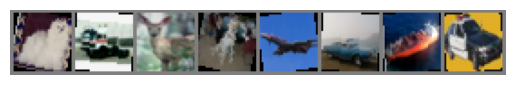

In [9]:
def imshow(img):
    img = img / 2 + 0.5   # unnormalize
    npimg = img.numpy()

    # Correct transpose: (C,H,W) → (H,W,C)
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")
    plt.show()

# Show images
imshow(torchvision.utils.make_grid(images[:8]))


In [10]:
class_names =train_dataset.classes


In [11]:
[class_names[i] for i in labels[:8]]

['dog', 'truck', 'deer', 'dog', 'airplane', 'automobile', 'ship', 'automobile']

In [12]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=nn.Sequential(
            nn.Conv2d(3,32,kernel_size=(3,3),padding="same"),# output: (32, 32,32)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2)),# output: (32,16,16)
            nn.Conv2d(32,64,kernel_size=(3,3)), # output : (64,14,14)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2)) # output: (64,7,7)
        )
        self.fc_network=nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*7*7,700),
            nn.ReLU(),
            nn.Linear(700,120),
            nn.ReLU(),
            nn.Linear(120,10)
        )
    def forward(self,x):
        x=self.network(x)
        x=self.fc_network(x)
        return x


In [13]:
CNN()

CNN(
  (network): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  )
  (fc_network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=700, bias=True)
    (2): ReLU()
    (3): Linear(in_features=700, out_features=120, bias=True)
    (4): ReLU()
    (5): Linear(in_features=120, out_features=10, bias=True)
  )
)

In [14]:
# Hyperparameters
num_epochs = 10
learning_rate = 0.001

model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [15]:
# Training loop
total_step = len(train_loader)
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        if (i+1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{total_step}], Loss: {loss.item():.4f}")

# Testing the model
model.eval()
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Accuracy of the model on the 10000 test images: {100 * correct / total:.2f}%")

Epoch [1/10], Step [100/500], Loss: 1.7181
Epoch [1/10], Step [200/500], Loss: 1.6524
Epoch [1/10], Step [300/500], Loss: 1.3030
Epoch [1/10], Step [400/500], Loss: 1.1654
Epoch [1/10], Step [500/500], Loss: 1.0459
Epoch [2/10], Step [100/500], Loss: 1.2179
Epoch [2/10], Step [200/500], Loss: 1.0879
Epoch [2/10], Step [300/500], Loss: 1.0336
Epoch [2/10], Step [400/500], Loss: 0.9596
Epoch [2/10], Step [500/500], Loss: 0.9387
Epoch [3/10], Step [100/500], Loss: 1.0593
Epoch [3/10], Step [200/500], Loss: 0.9989
Epoch [3/10], Step [300/500], Loss: 0.9181
Epoch [3/10], Step [400/500], Loss: 0.9487
Epoch [3/10], Step [500/500], Loss: 0.8029
Epoch [4/10], Step [100/500], Loss: 0.8973
Epoch [4/10], Step [200/500], Loss: 0.9418
Epoch [4/10], Step [300/500], Loss: 0.6982
Epoch [4/10], Step [400/500], Loss: 0.7033
Epoch [4/10], Step [500/500], Loss: 0.8811
Epoch [5/10], Step [100/500], Loss: 0.8078
Epoch [5/10], Step [200/500], Loss: 0.6892
Epoch [5/10], Step [300/500], Loss: 0.7211
Epoch [5/10

# Transfer Learning

In [16]:
from torchvision import models
model=models.googlenet(weights="DEFAULT")
model.fc=nn.Linear(model.fc.in_features,len(class_names))



Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to C:\Users\Trijesh Kondapuram/.cache\torch\hub\checkpoints\googlenet-1378be20.pth
100%|██████████| 49.7M/49.7M [00:34<00:00, 1.51MB/s]


In [17]:
# Hyperparameters
num_epochs = 10
learning_rate = 0.001

model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [18]:
# Training loop
total_step = len(train_loader)
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        if (i+1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{total_step}], Loss: {loss.item():.4f}")

# Testing the model
model.eval()
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Accuracy of the model on the 10000 test images: {100 * correct / total:.2f}%")

Epoch [1/10], Step [100/500], Loss: 1.0637
Epoch [1/10], Step [200/500], Loss: 1.0090
Epoch [1/10], Step [300/500], Loss: 1.2379
Epoch [1/10], Step [400/500], Loss: 1.0551
Epoch [1/10], Step [500/500], Loss: 0.7616
Epoch [2/10], Step [100/500], Loss: 0.7959
Epoch [2/10], Step [200/500], Loss: 0.5920
Epoch [2/10], Step [300/500], Loss: 0.6463
Epoch [2/10], Step [400/500], Loss: 0.7546
Epoch [2/10], Step [500/500], Loss: 0.7931
Epoch [3/10], Step [100/500], Loss: 0.9467
Epoch [3/10], Step [200/500], Loss: 0.5802
Epoch [3/10], Step [300/500], Loss: 0.8462
Epoch [3/10], Step [400/500], Loss: 0.5640
Epoch [3/10], Step [500/500], Loss: 0.7394
Epoch [4/10], Step [100/500], Loss: 0.6359
Epoch [4/10], Step [200/500], Loss: 0.6067
Epoch [4/10], Step [300/500], Loss: 0.5931
Epoch [4/10], Step [400/500], Loss: 0.6050
Epoch [4/10], Step [500/500], Loss: 0.5282
Epoch [5/10], Step [100/500], Loss: 0.5696
Epoch [5/10], Step [200/500], Loss: 0.5757
Epoch [5/10], Step [300/500], Loss: 0.4440
Epoch [5/10

In [26]:
import torch

model = torch.hub.load(
    'NVIDIA/DeepLearningExamples:torchhub',
    'nvidia_efficientnet_widese_b4',
    pretrained=True
)

Using cache found in C:\Users\Trijesh Kondapuram/.cache\torch\hub\NVIDIA_DeepLearningExamples_torchhub


In [27]:
print(model.classifier)

Sequential(
  (pooling): AdaptiveAvgPool2d(output_size=1)
  (squeeze): Flatten()
  (dropout): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=1792, out_features=1000, bias=True)
)


In [28]:
num_features = model.classifier.fc.in_features
model.classifier.fc = nn.Linear(num_features, len(class_names))

In [30]:
device

'cuda'

In [31]:
# Hyperparameters
num_epochs = 10
learning_rate = 0.001

model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
# Training loop
total_step = len(train_loader)
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        if (i+1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{total_step}], Loss: {loss.item():.4f}")

# Testing the model
model.eval()
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Accuracy of the model on the 10000 test images: {100 * correct / total:.2f}%")

Epoch [1/10], Step [100/500], Loss: 1.2386
Epoch [1/10], Step [200/500], Loss: 1.0897
Epoch [1/10], Step [300/500], Loss: 1.0440
Epoch [1/10], Step [400/500], Loss: 0.8601
Epoch [1/10], Step [500/500], Loss: 0.6242
Epoch [2/10], Step [100/500], Loss: 0.7640
Epoch [2/10], Step [200/500], Loss: 0.8075
Epoch [2/10], Step [300/500], Loss: 0.4967
Epoch [2/10], Step [400/500], Loss: 0.6427
Epoch [2/10], Step [500/500], Loss: 0.5309
Epoch [3/10], Step [100/500], Loss: 0.5301
Epoch [3/10], Step [200/500], Loss: 0.3561
Epoch [3/10], Step [300/500], Loss: 0.5183
Epoch [3/10], Step [400/500], Loss: 0.5607
Epoch [3/10], Step [500/500], Loss: 0.4989
Epoch [4/10], Step [100/500], Loss: 0.6299
Epoch [4/10], Step [200/500], Loss: 0.4089
Epoch [4/10], Step [300/500], Loss: 0.2484
Epoch [4/10], Step [400/500], Loss: 0.3693
Epoch [4/10], Step [500/500], Loss: 0.4940
Epoch [5/10], Step [100/500], Loss: 0.4046
Epoch [5/10], Step [200/500], Loss: 0.3866
Epoch [5/10], Step [300/500], Loss: 0.3561
Epoch [5/10

In [1]:
from transformers import BertTokenizer, BertModel


In [2]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
text = "I love apple"
encoded_input = tokenizer(text, return_tensors='pt')
output = model(**encoded_input)


NameError: name 'model' is not defined